# PathSnap — Bayesian hyperparameter optimisation (Histogram Gradient Boosting)

We tune Histogram Gradient Boosting (HGB), the tuning candidate chosen in `model_comparison.ipynb` (section 5): the
three best untuned models were within 0.26 pp, and HGB showed clear headroom (unstable iteration history with no
L2 penalty) while training 10-20× faster than the random forest and the MLP. We use **Optuna's TPE sampler**,
a Bayesian optimisation method: instead of trying settings at random or on a grid, it builds a probabilistic model
of "which settings gave good scores so far" (two density estimates, one for good trials and one for bad trials)
and proposes the next setting where good results are most likely relative to bad ones. Each new trial therefore
uses everything learned from the earlier ones.

- **Objective:** mean observation-level top-1 accuracy over GroupKFold(5) by trip on the 80 train trips (the same
  folds as every model notebook). student_test and evaluator data are **not** used in the search.
- **Cost control:** each trial trains on 15% of the training fixes per fold (the untuned baseline used 40%), and
  Optuna's **median pruner** stops a trial early if after 2+ folds it is below the median of earlier trials at the
  same fold. The best setting is then re-run with the full 40% recipe, so tuned vs untuned is a like-for-like
  comparison.
- **Search record:** every trial is kept in an SQLite study file and exported to CSV.

In [1]:
import json, sys, time
sys.path.insert(0, ".")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from sklearn.ensemble import HistGradientBoostingClassifier
from pathsnap_common import *

train = load_partition("train"); test = load_partition("student_test")
X, y, gid = matrix(train), train.y.values, train.gid.values
keep, tidx = train.keep_train.values, train.tidx.values
FOLDS = make_folds(train)
SEARCH_FRAC, N_TRIALS = 0.15, 30
BO = OUT_DIR / "bayes_opt"; BO.mkdir(parents=True, exist_ok=True)

/usr/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Search space

| Hyperparameter | Range / distribution | Why this range |
|---|---|---|
| `learning_rate` | log-uniform 0.02 – 0.3 | smaller steps generalise better but need more trees; log scale because the effect is multiplicative |
| `max_iter` | integer 100 – 600 (step 50) | number of trees; paired with the learning rate |
| `max_leaf_nodes` | integer, log 15 – 255 | tree size = how many feature interactions one tree can express |
| `min_samples_leaf` | integer, log 10 – 1 000 | larger leaves = smoother, less noise-fitting |
| `l2_regularization` | log-uniform 1e-3 – 10 | shrinks leaf values |
| `max_features` | uniform 0.4 – 1.0 | share of features considered per split (adds randomness, like a forest) |

The untuned model used `learning_rate=0.1, max_iter=200, max_leaf_nodes=31, min_samples_leaf=20,
l2_regularization=0, max_features=1.0`, all inside the space.

In [2]:
def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        max_iter=trial.suggest_int("max_iter", 100, 600, step=50),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 15, 255, log=True),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 1000, log=True),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
        max_features=trial.suggest_float("max_features", 0.4, 1.0),
    )
    scores = []
    for k, vt in enumerate(FOLDS):
        is_val = np.isin(tidx, vt)
        tr = subsample_fixes(np.flatnonzero(~is_val & keep), gid, SEARCH_FRAC, SEED + k)
        va = np.flatnonzero(is_val & keep)
        m = HistGradientBoostingClassifier(**params, early_stopping=False, random_state=SEED).fit(X[tr], y[tr])
        scores.append(quick_top1_logloss(gid[va], y[va], m.predict_proba(X[va])[:, 1])[0])
        trial.report(float(np.mean(scores)), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return float(np.mean(scores))


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", study_name="hgb_top1",
                            storage=f"sqlite:///{BO / 'study.db'}", load_if_exists=True,
                            sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=8),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
# trial 0 = the untuned configuration, so the search starts from (and is compared against) the baseline
if len(study.trials) == 0:
    study.enqueue_trial(dict(learning_rate=0.1, max_iter=200, max_leaf_nodes=31, min_samples_leaf=20,
                             l2_regularization=1e-3, max_features=1.0))
t0 = time.time()
remaining = N_TRIALS - len(study.trials)
if remaining > 0:
    study.optimize(objective, n_trials=remaining,
                   callbacks=[lambda s, t: print(f"trial {t.number:2d} {t.state.name:8s} value={t.value} "
                                                 f"best={s.best_value:.4f} ({time.time() - t0:.0f}s)", flush=True)])
search_s = time.time() - t0
print(f"search time {search_s / 60:.1f} min; best CV top-1 (15% recipe) {study.best_value:.4f}")
print("best params:", study.best_params)

trial  0 COMPLETE value=0.8684762703380567 best=0.8685 (62s)


trial  1 COMPLETE value=0.8722819273771293 best=0.8723 (389s)


trial  2 COMPLETE value=0.8729334700704442 best=0.8729 (651s)


trial  3 COMPLETE value=0.8689556535402214 best=0.8729 (711s)


trial  4 COMPLETE value=0.873430898542918 best=0.8734 (856s)


trial  5 COMPLETE value=0.873253556269843 best=0.8734 (1024s)


... (20 outputs left out)

trial 26 COMPLETE value=0.8743708543343658 best=0.8748 (2323s)


trial 27 PRUNED   value=0.8830688517131091 best=0.8748 (2368s)


trial 28 PRUNED   value=0.8828810919828081 best=0.8748 (2402s)


search time 40.0 min; best CV top-1 (15% recipe) 0.8748
best params: {'learning_rate': 0.020575857872224046, 'max_iter': 200, 'max_leaf_nodes': 118, 'min_samples_leaf': 16, 'l2_regularization': 0.26708771359289446, 'max_features': 0.638316060131456}


## 2. Search record

In [3]:
trials = study.trials_dataframe()
trials.to_csv(BO / "trials.csv", index=False)
print(trials.state.value_counts().to_dict())
trials.sort_values("value", ascending=False).head(10).round(4)

{'COMPLETE': 16, 'PRUNED': 13}


/tmp/ipykernel_1366530/3933510657.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  trials.sort_values("value", ascending=False).head(10).round(4)


,number,value,datetime_start,datetime_complete,duration,params_l2_regularization,params_learning_rate,params_max_features,params_max_iter,params_max_leaf_nodes,params_min_samples_leaf,system_attrs_fixed_params,system_attrs_tpe:relative_params:0,state
22,22,0.8859,2026-11-18 15:04:21.355086,2026-11-18 15:05:06.065815,0 days 00:00:44.710729,0.3660,0.0417,0.6920,200,119,10,NaN,"{""l2_regularization"": 0.36602455026759373, ""le...",PRUNED
6,6,0.8854,2026-11-18 14:47:15.177418,2026-11-18 14:48:04.170967,0 days 00:00:48.993549,7.2867,0.1036,0.8850,150,17,789,NaN,NaN,PRUNED
23,23,0.8832,2026-11-18 15:05:06.087361,2026-11-18 15:05:28.652581,0 days 00:00:22.565220,0.3247,0.0295,0.6125,150,232,26,NaN,"{""l2_regularization"": 0.3246717412064427, ""lea...",PRUNED
18,18,0.8832,2026-11-18 15:01:36.374373,2026-11-18 15:01:51.072534,0 days 00:00:14.698161,0.1495,0.0372,0.8536,100,118,21,NaN,"{""l2_regularization"": 0.1494856848071414, ""lea...",PRUNED
27,27,0.8831,2026-11-18 15:08:54.274678,2026-11-18 15:09:39.267520,0 days 00:00:44.992842,1.1750,0.0282,0.5678,350,168,38,NaN,"{""l2_regularization"": 1.175004304024182, ""lear...",PRUNED
24,24,0.8829,2026-11-18 15:05:28.671010,2026-11-18 15:05:46.139166,0 days 00:00:17.468156,1.0176,0.0209,0.7380,150,137,23,NaN,"{""l2_regularization"": 1.0175882789874184, ""lea...",PRUNED
28,28,0.8829,2026-11-18 15:09:39.287683,2026-11-18 15:10:12.743611,0 days 00:00:33.455928,1.1578,0.0315,0.6040,250,168,12,NaN,"{""l2_regularization"": 1.1577830381752392, ""lea...",PRUNED
11,11,0.8826,2026-11-18 14:52:31.665957,2026-11-18 14:53:02.065757,0 days 00:00:30.399800,1.6743,0.0908,0.6735,100,117,36,NaN,"{""l2_regularization"": 1.67426143657328, ""learn...",PRUNED
15,15,0.8825,2026-11-18 14:59:53.532401,2026-11-18 15:00:24.062972,0 days 00:00:30.530571,0.0178,0.0252,0.7290,200,194,223,NaN,"{""l2_regularization"": 0.017788953784002765, ""l...",PRUNED
17,17,0.8824,2026-11-18 15:00:57.739734,2026-11-18 15:01:36.352665,0 days 00:00:38.612931,0.1871,0.0243,0.7727,300,120,707,NaN,"{""l2_regularization"": 0.18708047572299746, ""le...",PRUNED


/tmp/ipykernel_1366530/2240585487.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study); ax.figure.set_size_inches(8, 3.6); ax.figure.tight_layout()


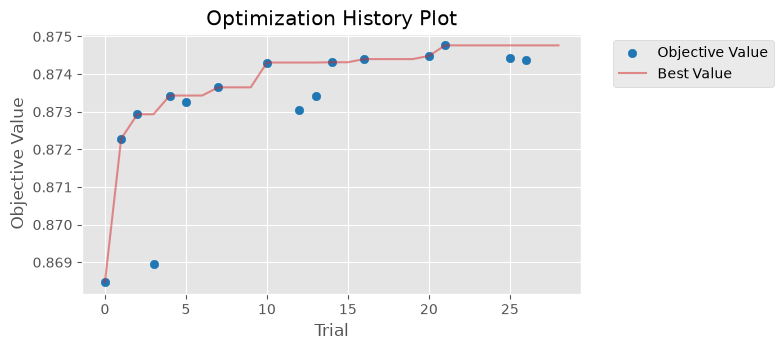

/tmp/ipykernel_1366530/2240585487.py:4: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study); ax.figure.set_size_inches(7, 3.4); ax.figure.tight_layout()


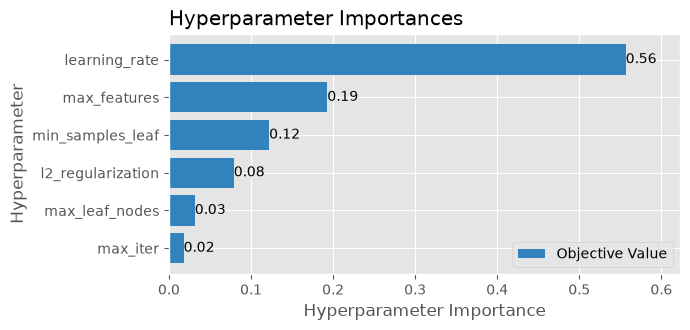

/tmp/ipykernel_1366530/2240585487.py:6: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  axs = plot_slice(study); f = axs[0].figure; f.set_size_inches(15, 3.4); f.tight_layout()
/tmp/ipykernel_1366530/2240585487.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  axs = plot_slice(study); f = axs[0].figure; f.set_size_inches(15, 3.4); f.tight_layout()


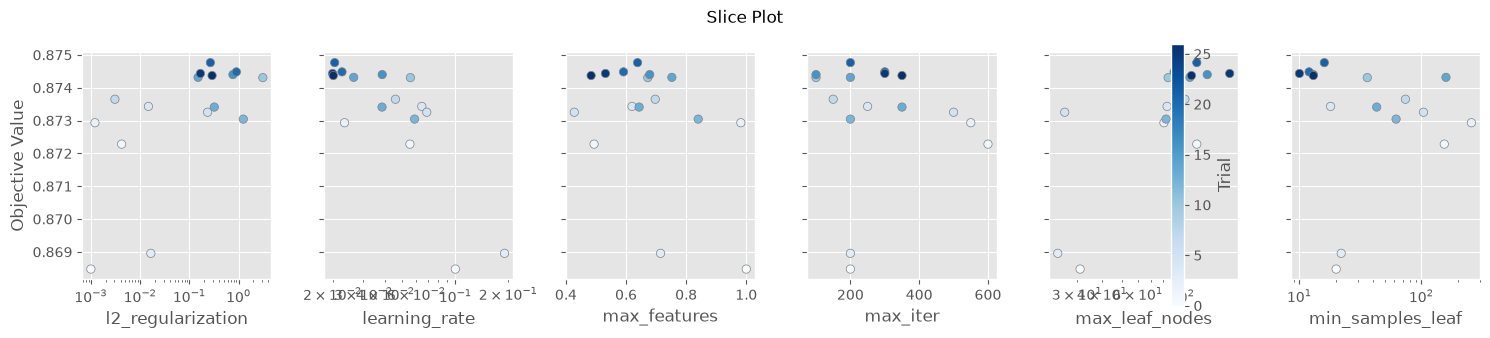

In [4]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances, plot_slice
ax = plot_optimization_history(study); ax.figure.set_size_inches(8, 3.6); ax.figure.tight_layout()
ax.figure.savefig(BO / "fig_history.png", dpi=150); plt.show()
ax = plot_param_importances(study); ax.figure.set_size_inches(7, 3.4); ax.figure.tight_layout()
ax.figure.savefig(BO / "fig_importance.png", dpi=150); plt.show()
axs = plot_slice(study); f = axs[0].figure; f.set_size_inches(15, 3.4); f.tight_layout()
f.savefig(BO / "fig_slice.png", dpi=150); plt.show()

## 3. Refit the best configuration with the full recipe and compare with the untuned model

Same folds, same 40% training share, same student_test evaluation as `models/05_hist_gradient_boosting.ipynb`.

In [5]:
BEST = dict(study.best_params)


def make_tuned():
    return HistGradientBoostingClassifier(**BEST, early_stopping=False, random_state=SEED)


cv_t, oof_t, _ = run_cv(make_tuned, train, 0.4, label="hgb_tuned")
model_t, p_t, res_t, preds_t = fit_and_test(make_tuned, train, test, 0.4)
save_results("hgb_tuned", "Boosting", dict(**BEST, early_stopping=False, train_frac=0.4, random_state=SEED),
             cv_t, res_t, model=model_t, oof=oof_t, p_test=p_t,
             extra=dict(search=dict(n_trials=len(study.trials), search_minutes=search_s / 60, objective="mean CV top-1",
                                    sampler="TPE", pruner="median", search_frac=SEARCH_FRAC)))

[hgb_tuned] fold 1: train top-1 0.8924 | val top-1 0.8618 | val log loss 0.0777 | fit 15s


[hgb_tuned] fold 2: train top-1 0.8853 | val top-1 0.9056 | val log loss 0.0525 | fit 15s


[hgb_tuned] fold 3: train top-1 0.8967 | val top-1 0.8569 | val log loss 0.0679 | fit 14s


[hgb_tuned] fold 4: train top-1 0.8832 | val top-1 0.9214 | val log loss 0.0428 | fit 15s


[hgb_tuned] fold 5: train top-1 0.9036 | val top-1 0.8330 | val log loss 0.0873 | fit 16s


{'name': 'hgb_tuned',
 'family': 'Boosting',
 'config': {'learning_rate': 0.020575857872224046,
  'max_iter': 200,
  'max_leaf_nodes': 118,
  'min_samples_leaf': 16,
  'l2_regularization': 0.26708771359289446,
  'max_features': 0.638316060131456,
  'early_stopping': False,
  'train_frac': 0.4,
  'random_state': 42},
 'cv_mean': {'val_trips': 16.0,
  'train_rows': 576251.8,
  'fit_s': 14.818186712265014,
  'predict_s': 3.1361616134643553,
  'predict_ms_per_1k_fixes': 76.64335446192145,
  'train_top1': 0.89225,
  'train_logloss': 0.05727112933424498,
  'val_top1': 0.8757567094795184,
  'val_logloss': 0.06564303636550903,
  'val_macro_f1': 0.7588650845863218,
  'val_top1_all': 0.7674513203450661,
  'val_continuity': 0.9690027345521521,
  'val_route_f1': 0.8791168078233167,
  'val_precision': 0.8886565244228523,
  'val_recall': 0.8528107949208884,
  'val_f1': 0.8703375448237137},
 'cv_std': {'val_trips': 0.0,
  'train_rows': 1896.1275537262782,
  'fit_s': 0.6475800836886402,
  'predict_s':

In [6]:
U = json.load(open(OUT_DIR / "hist_gradient_boosting" / "results.json"))
cv_u = pd.read_csv(OUT_DIR / "hist_gradient_boosting" / "cv_folds.csv")
T = json.load(open(OUT_DIR / "hgb_tuned" / "results.json"))
cmp = pd.DataFrame({
    "untuned": [cv_u.val_macro_f1.mean(), cv_u.val_top1.mean(), U["student_test"]["top1"], U["student_test"]["macro_f1"],
                U["student_test"]["logloss"], U["student_test"]["predict_ms_per_1k_fixes"], U["student_test"]["fit_s"]],
    "tuned": [cv_t.val_macro_f1.mean(), cv_t.val_top1.mean(), res_t["top1"], res_t["macro_f1"], res_t["logloss"],
              res_t["predict_ms_per_1k_fixes"], res_t["fit_s"]]},
    index=["CV macro F1", "CV top-1", "student_test top-1", "student_test macro F1", "student_test log loss",
           "inference ms / 1k fixes", "training time (s)"])
cmp["change"] = cmp.tuned - cmp.untuned
cmp.to_csv(BO / "tuned_vs_untuned.csv")
d = cv_t.val_top1.values - cv_u.val_top1.values
print("per-fold CV top-1 gain (pp):", np.round(d * 100, 2), f"-> better in {(d > 0).sum()}/5 folds")
cmp.round(4)

per-fold CV top-1 gain (pp): [0.63 0.49 0.43 0.66 0.74] -> better in 5/5 folds


,untuned,tuned,change
CV macro F1,0.7353,0.7589,0.0235
CV top-1,0.8699,0.8758,0.0059
student_test top-1,0.8864,0.8930,0.0066
student_test macro F1,0.7548,0.7808,0.0260
student_test log loss,0.0637,0.0526,-0.0111
inference ms / 1k fixes,48.1305,86.9093,38.7788
training time (s),8.6791,18.3333,9.6542


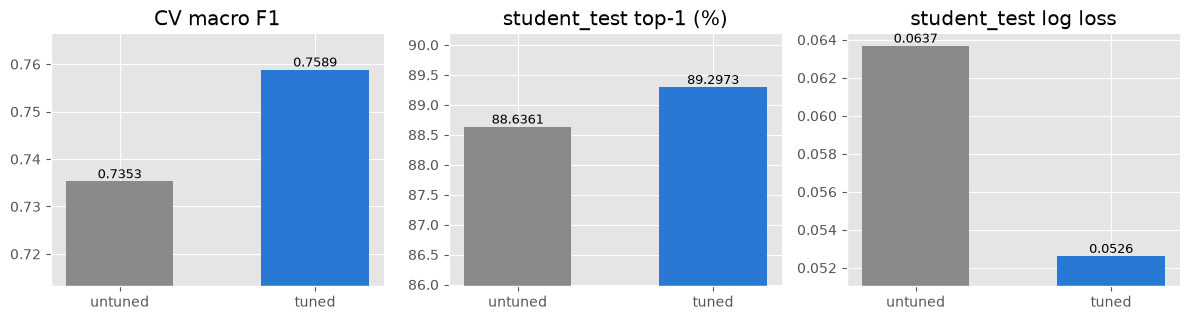

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, (lab, u, t) in zip(ax, [("CV macro F1", cmp.untuned.iloc[0], cmp.tuned.iloc[0]),
                                ("student_test top-1 (%)", cmp.untuned.iloc[2] * 100, cmp.tuned.iloc[2] * 100),
                                ("student_test log loss", cmp.untuned.iloc[4], cmp.tuned.iloc[4])]):
    a.bar(["untuned", "tuned"], [u, t], color=[GREY, BLUE], width=.55)
    lo = min(u, t); a.set_ylim(lo * 0.97, max(u, t) * 1.01); a.set_title(lab)
    for i, v in enumerate([u, t]): a.text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(BO / "fig_tuned_vs_untuned.png", dpi=150); plt.show()

## 4. Export the final model

The tuned model, the feature list and the configuration are written to `models_out/final_model/`. These are the
artifacts the API will load.

In [8]:
import joblib, shutil
FINAL = OUT_DIR / "final_model"; FINAL.mkdir(exist_ok=True)
joblib.dump(model_t, FINAL / "classifier.joblib", compress=3)
json.dump(dict(model="HistGradientBoostingClassifier", params=BEST, features=FEATURES,
               candidate_radius_m=50, min_candidates=5, seed=SEED), open(FINAL / "classifier_config.json", "w"), indent=1)
print(sorted(p.name for p in FINAL.iterdir()))

['classifier.joblib', 'classifier_config.json']
